<a href="https://colab.research.google.com/github/Dishantchd/DS-practical/blob/main/Ds-practical3/DSPractical_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("evals.csv")
df

,course_id,prof_id,score,rank,ethnicity,gender,language,age,cls_perc_eval,cls_did_eval,...,cls_credits,bty_f1lower,bty_f1upper,bty_f2upper,bty_m1lower,bty_m1upper,bty_m2upper,bty_avg,pic_outfit,pic_color
0,1,1,4.7,tenure track,minority,female,english,36,55.81395,24,...,multi credit,5,7,6,2,4,6,5.000,not formal,color
1,2,1,4.1,tenure track,minority,female,english,36,68.80000,86,...,multi credit,5,7,6,2,4,6,5.000,not formal,color
2,3,1,3.9,tenure track,minority,female,english,36,60.80000,76,...,multi credit,5,7,6,2,4,6,5.000,not formal,color
3,4,1,4.8,tenure track,minority,female,english,36,62.60163,77,...,multi credit,5,7,6,2,4,6,5.000,not formal,color
4,5,2,4.6,tenured,not minority,male,english,59,85.00000,17,...,multi credit,4,4,2,2,3,3,3.000,not formal,color
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458,459,93,4.5,tenure track,not minority,male,english,32,60.46511,52,...,multi credit,6,6,9,7,8,5,6.833,not formal,color
459,460,94,3.5,tenure track,minority,female,non-english,42,57.14286,48,...,multi credit,3,8,7,4,6,4,5.333,not formal,color
460,461,94,4.4,tenure track,minority,female,non-english,42,77.61194,52,...,multi credit,3,8,7,4,6,4,5.333,not formal,color
461,462,94,4.4,tenure track,minority,female,non-english,42,81.81818,54,...,multi credit,3,8,7,4,6,4,5.333,not formal,color


The dataset contains information about 463 professors and their teaching evaluations. It includes details such as professor ID, course ID, evaluation score, age, gender, ethnicity, teaching experience, and appearance ratings. Each row represents a record, and each column represents a different variable.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   course_id      463 non-null    int64  
 1   prof_id        463 non-null    int64  
 2   score          463 non-null    float64
 3   rank           463 non-null    object 
 4   ethnicity      463 non-null    object 
 5   gender         463 non-null    object 
 6   language       463 non-null    object 
 7   age            463 non-null    int64  
 8   cls_perc_eval  463 non-null    float64
 9   cls_did_eval   463 non-null    int64  
 10  cls_students   463 non-null    int64  
 11  cls_level      463 non-null    object 
 12  cls_profs      463 non-null    object 
 13  cls_credits    463 non-null    object 
 14  bty_f1lower    463 non-null    int64  
 15  bty_f1upper    463 non-null    int64  
 16  bty_f2upper    463 non-null    int64  
 17  bty_m1lower    463 non-null    int64  
 18  bty_m1uppe

The dataset has 463 records and 23 columns. It contains numerical and categorical data. There are no missing values in any column, which means the dataset is complete and ready for further analysis.

In [ ]:
df.describe()

,course_id,prof_id,score,age,cls_perc_eval,cls_did_eval,cls_students,bty_f1lower,bty_f1upper,bty_f2upper,bty_m1lower,bty_m1upper,bty_m2upper,bty_avg
count,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000
mean,232.000000,45.153348,4.174730,48.365011,74.427788,36.624190,55.177106,3.963283,5.019438,5.213823,3.412527,4.146868,4.751620,4.417844
std,133.800847,27.547052,0.543865,9.802742,16.756311,45.018481,75.072800,1.873936,1.934437,2.018224,1.637102,2.110586,1.575266,1.527380
min,1.000000,1.000000,2.300000,29.000000,10.416670,5.000000,8.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.667000
25%,116.500000,20.000000,3.800000,42.000000,62.696165,15.000000,19.000000,2.000000,4.000000,4.000000,2.000000,3.000000,4.000000,3.167000
50%,232.000000,43.000000,4.300000,48.000000,76.923080,23.000000,29.000000,4.000000,5.000000,5.000000,3.000000,4.000000,5.000000,4.333000
75%,347.500000,70.500000,4.600000,57.000000,87.249170,40.000000,60.000000,5.000000,7.000000,6.000000,5.000000,5.000000,6.000000,5.500000
max,463.000000,94.000000,5.000000,73.000000,100.000000,380.000000,581.000000,8.000000,9.000000,10.000000,7.000000,9.000000,9.000000,8.167000


The average professor evaluation score is approximately 4.17 out of 5, which indicates generally positive teaching evaluations. The average age of professors is around 48 years. The average class evaluation participation percentage is approximately 74.43%.

The minimum evaluation score is 2.3, while the maximum is 5.0. This shows that professors received different levels of student feedback.

In [ ]:
# Calculate the percentage of visible minorities are tenure professors. Will you say that tenure status differed if teacher was a visible minority?
minority = df[df['ethnicity'] == 'minority']
tenured_minority = minority[minority['rank'] == 'tenured']
percentage = len(tenured_minority) / len(minority) * 100
print("Percentage:", percentage)

Percentage: 40.625


The analysis shows that approximately 40.63% of minority professors are tenured. This means that out of all professors belonging to the minority group, around 41% have achieved tenured status.

The remaining percentage belongs to professors who are either teaching or on the tenure track.

In [ ]:
print(pd.crosstab(df['ethnicity'], df['rank']))

rank          teaching  tenure track  tenured
ethnicity                                    
minority            10            28       26
not minority        92            80      227


The table shows the distribution of professors based on ethnicity and professional rank.

Among minority professors, 26 are tenured, 28 are on the tenure track, and 10 are teaching professors.

Among non-minority professors, 227 are tenured, 80 are on the tenure track, and 92 are teaching professors.

The number of tenured non-minority professors is much higher than the number of tenured minority professors. However, this table alone does not prove that ethnicity affects tenure status.

In [ ]:
tenured_age = df[df['rank']=='tenured']['age']
untenured_age = df[df['rank']!='tenured']['age']

print("Tenured Mean:", tenured_age.mean())
print("Tenured SD:", tenured_age.std())

print("Untenured Mean:", untenured_age.mean())
print("Untenured SD:", untenured_age.std())

Tenured Mean: 51.88932806324111
Tenured SD: 8.654501807200475
Untenured Mean: 44.11904761904762
Untenured SD: 9.43170460310381


The average age of tenured professors is approximately 52 years. The standard deviation of 8.65 indicates that their ages generally vary around the average.

The average age of untenured professors is approximately 44 years. Their standard deviation is 9.43, which shows some variation in their ages.

When compared with tenured professors, untenured professors are younger on average by approximately 8 years.

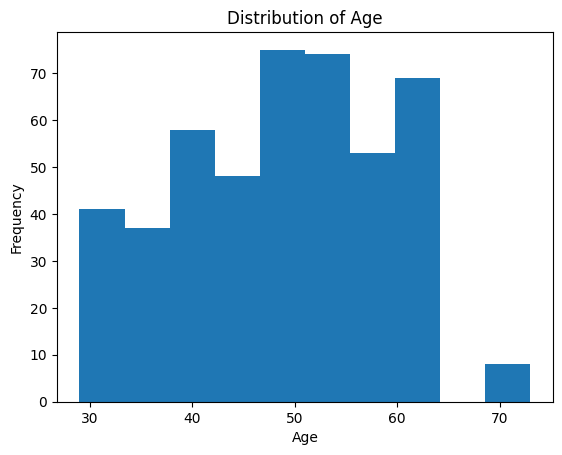

In [ ]:
plt.hist(df['age'], bins=10)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Age")
plt.show()

The histogram shows the age distribution of professors in the dataset.

Most professors are between 45 and 65 years old. The highest number of professors falls approximately in the age group of 48–55 years. Very few professors are above 65 years.

This indicates that most professors in the dataset belong to the middle-age group.

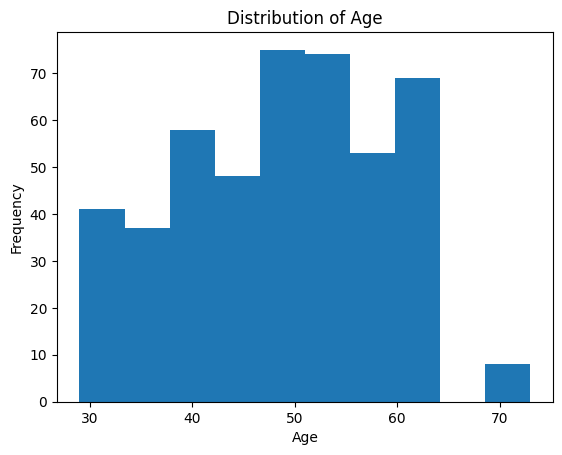

In [ ]:
plt.hist(df['age'], bins=10)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Age")
plt.show()

The horizontal bar chart compares the number of male and female individuals using the given values.

The chart shows 200 males and 150 females. This means that the male count is higher than the female count by 50

<BarContainer object of 2 artists>

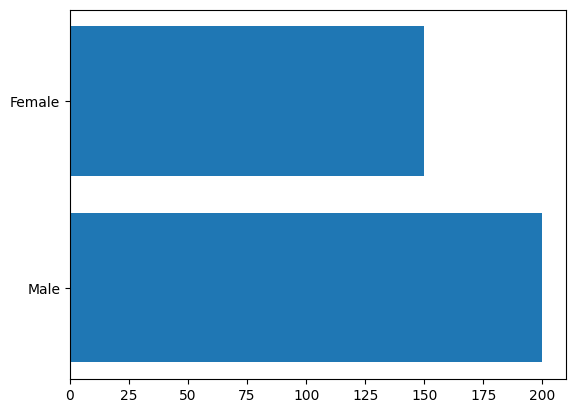

In [ ]:
plt.barh(['Male','Female'], [200,150])

The vertical bar chart represents the same information as the horizontal bar chart, but uses vertical bars.

It shows that the male count (200) is higher than the female count (150). This chart makes it easy to compare the two categories visually.

<BarContainer object of 2 artists>

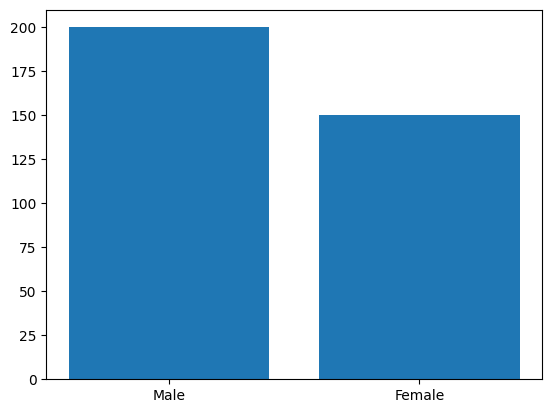

In [ ]:
plt.bar(['Male','Female'], [200,150])

In [ ]:
# Q5
median_score = df[df['rank']=='tenured']['score'].median()
print("Median Evaluation Score:", median_score)

Median Evaluation Score: 4.2


The median evaluation score of tenured professors is 4.2. This means that the middle evaluation score, when all scores are arranged in ascending order, is 4.2.

It indicates that tenured professors generally receive positive evaluation scores from students.

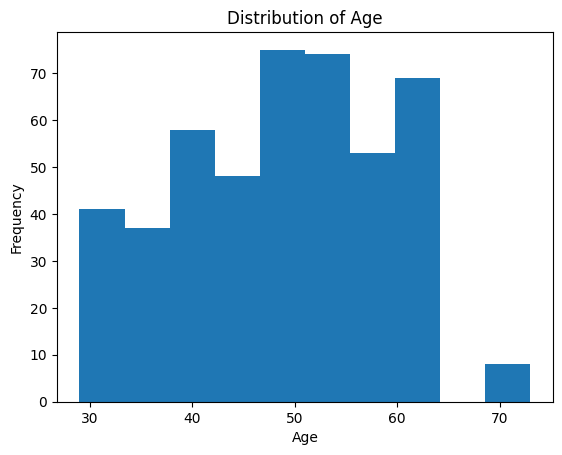

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df['age'], bins=10)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()